In [3]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, vNtoQ_B, PQM, _find_muB_muK_star

n0 = 0.16 * const.MeV_fm**3

def Get_Two_as(T, n_crit, Deln, m_s, param, NM_type, method):
    '''
    Computes NM to SQM phase boundary velocity 

    Parameters:
    - T        : temperature
    - n_crit   : critical density for 1st order phase transition
    - Deln     : Messures how far away from equilibrium
    - m_s      : strange quark mass
    - param    : mean field theory model settings for nuclear matter
    - NM_type  : assumptions for nuclear matter, choose from:
                 - "Beta_eq" for beta equilibriated nuclear matter
                 - "PNM" for pure neutron matter
                 - "SYM" for symmetric nuclear matter
    - method   : ways to calculate velocity
                 - "numerical" in principle more precise, but have numerical noise
                 - "analytical" analytical approximation, direct, faster, and robust, ~ 10% difference with numerical method

    Returns:
    - velocity of phase boundary in meters per second
    '''

    def PNM(mu_B, Temp):
        if NM_type == "Beta_eq":
            rmf_sol = RMFsolve_mu(mub = mu_B, Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
                )
            return (pressure_RMF(rmf_sol)).item()

        elif NM_type == "PNM":
            pre = RMFpressurePNM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
                )
            return float(pre.item())

        elif NM_type == "SYM":
            pre = RMFpressureSYM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
                )
            return float(pre.item())

        else:
            return ValueError("Nuclear matter type not defined.")


    def PNM_n(nB, Temp):
        if NM_type == "Beta_eq":
            rmf_sol = RMFsolve(nbext = nB, Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
                )
            return (pressure_RMF(rmf_sol)).item()

        elif NM_type == "PNM":
            pre = RMFpressurePNM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
                )
            return float(pre.item())

        elif NM_type == "SYM":
            pre = RMFpressureSYM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
                )
            return float(pre.item())

        else:
            return ValueError("Nuclear matter type not defined.")
  

    # solve for bag constant
    P_crit = PNM_n(n_crit, T)
    P_diff = lambda x: PNM(x, T) - P_crit
    muB_crit = fsolve(P_diff, 1050)[0]
    PQM_solve_for_B = lambda x: PQM(muB_crit, 0, x, T, m_s) - P_crit
    B_SQM = fsolve(PQM_solve_for_B, 180)[0]

    # solve for points Q and N at beta eq.
    DelP = PNM_n(n_crit + Deln, T) - P_crit
    PNM_minus_PShift = lambda x: PNM(x,T) - P_crit - DelP
    muB_N = fsolve(PNM_minus_PShift, 1050)[0]

    PQM_minus_Pshift = lambda x: PQM(x, 0, B_SQM, T, m_s) - P_crit - DelP
    muB_Q = fsolve(PQM_minus_Pshift, 1050)[0]

    # calculating aQstar
    if method == "numerical":
        epsilon = np.sqrt(np.finfo(float).eps)
        muB_star, muK_star = _find_muB_muK_star(PQM, P_crit + DelP, muB_N, B_SQM, T, m_s)
        PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B_SQM, T, m_s)
        grad_Qstar = approx_fprime(np.array([muB_star, muK_star]), PQM_wrap, epsilon)
        nB_Qstar = grad_Qstar[0]
        nK_Qstar = grad_Qstar[1]
        grad_Q = approx_fprime(np.array([muB_Q, 0]), PQM_wrap, epsilon)
        nB_Q = grad_Q[0]
        nK_Q = grad_Q[1]
        aQstar = (nK_Qstar - nK_Q)/nB_Q  
 
    elif method == "analytical":
        PQM_muB = lambda Mu: PQM(Mu, 0, B_SQM, T, m_s)
        PQM_muK = lambda Mu: PQM(muB_Q, Mu, B_SQM, T, m_s)
        ddPQM_ddmuK = Derivative(PQM_muK, n=2)
        dPQM_dmuK = Derivative(PQM_muK, n=1)
        dPQM_dmuB = Derivative(PQM_muB, n=1)
        chiK_Q = ddPQM_ddmuK(0)
        nB_Q = dPQM_dmuB(muB_Q)
        nK_Q = dPQM_dmuK(0)
        aQstar = np.sqrt(2*(muB_N - muB_Q)*chiK_Q / nB_Q)
        muK_star = np.sqrt(2 * nB_Q * (muB_N - muB_Q) / chiK_Q)
        PQM_solve_for_muBstar = lambda x: PQM(x, muK_star, B_SQM, T, m_s) - P_crit
        muB_star = fsolve(PQM_solve_for_muBstar, muB_Q)[0]

    else:
        raise RuntimeError(f"Input method unknown")
        return None

    # calculating aN
    PNM_wrap = lambda x: PNM(x, T)
    dPNM_dmuB = Derivative(PNM_wrap, n=1)
    nB_N = dPNM_dmuB(muB_N)
    aN = (nB_N - nK_Q) / nB_Q   

    return aQstar, aN

In [8]:
vNtoQ_nc(
    T = 1,
    n_crit = 2 * n0,
    Deln = 0.5 * n0,
    m_s = 0,
    param = para.paraQMCRMF3,
    NM_type = "PNM",
    method = "numerical"
)

(np.float64(676.2220939242709), np.float64(176.53683689506377))

In [47]:
import numpy as np
import matplotlib.pyplot as plt

N = 30
meth = "numerical"
nc = 2*n0
m_strange = 0

TT = np.hstack([np.linspace(1, 20, int(N*2/5)),np.linspace(20.5, 72, int(N*3/5))])
DD = np.linspace(0.01*n0, 0.5*n0, N)

a_diff = np.zeros([N, N])

for i in range(N):  # loop over T (rows)
    for j in range(N):  # loop over B (columns)
        aQ_tmp, aN_tmp = Get_Two_as(
            T = TT[i],
            n_crit = nc,
            Deln = DD[j],
            m_s = m_strange,
            param = para.paraQMCRMF3,
            NM_type = "PNM",
            method = meth
        )
        a_diff[i,j] = aN_tmp - aQ_tmp
        print(i, j, a_diff[i,j])

#np.save("aQstar_aN_n_crit="+str(nc/n0)+".npy", a_diff)

0 0 0.5036466206428558
0 1 0.46550329151715225
0 2 0.4394265022722047
0 3 0.4185877612657792
0 4 0.40088765535878446
0 5 0.3853278365032705
0 6 0.3713383048901687
0 7 0.3585720274300481
0 8 0.3467824148098482
0 9 0.33579756019520857
0 10 0.3255005336731266
0 11 0.3157772491127955
0 12 0.3065581722865644
0 13 0.29777819875161404
0 14 0.2893835917503991
0 15 0.28133737082473026
0 16 0.2736108914872881
0 17 0.2661592555709258
0 18 0.2589562984373509
0 19 0.25199390152052953
0 20 0.24523311770500067
0 21 0.2386676550615459
0 22 0.23228271310469428
0 23 0.22605846193298224
0 24 0.21999238492962297
0 25 0.21405668164231817
0 26 0.20825982618940597
0 27 0.20258123138826856
0 28 0.1970157323826907
0 29 0.19155628928540952
1 0 0.503382074241415
1 1 0.4652223482099345


KeyboardInterrupt: 

Text(0, 0.5, 'T  (MeV)')

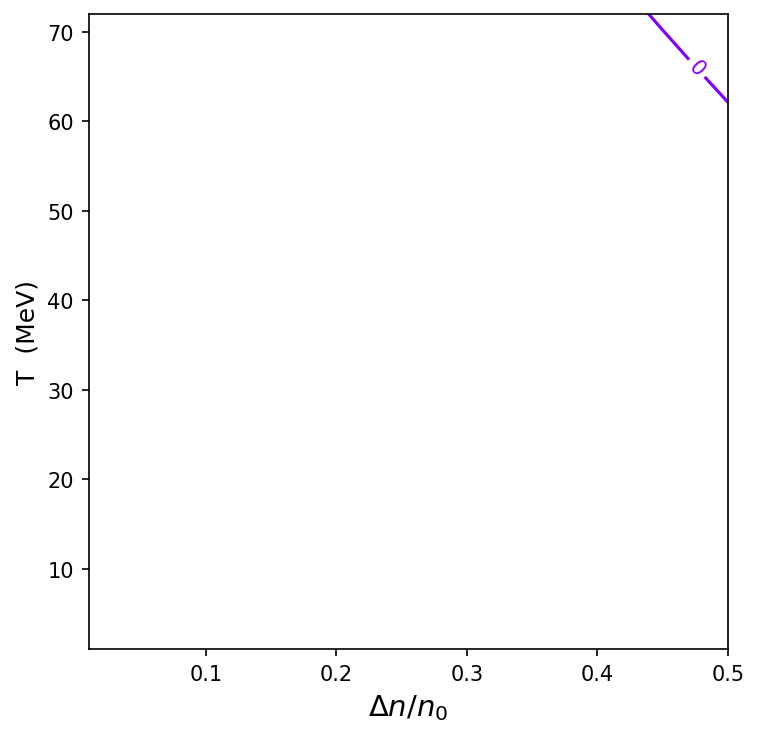

In [13]:
T_grid, D_grid = np.meshgrid(TT, DD)

plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Plotting


#V_old = np.load("DelP_T_B180_ms100.npy")
#D_grid_old, T_grid_old = np.meshgrid(np.linspace(1e6, 1e8, N)/4e8, np.linspace(1, 30, N))

contours = plt.contour(D_grid/n0, T_grid, a_diff.T, levels = [0], cmap="rainbow")
plt.clabel(contours, inline=True, fontsize=10)

#plt.title(r"Contour of $v_{N\to Q}^{max}$ in ($m\cdot s^{-1}$) for $n_{crit}=$"+str(nc/n0)+r"$n_0$" )
plt.xlabel(r"$\Delta n / n_{0}$", fontsize=14)
plt.ylabel("T  (MeV)", fontsize=12)

#plt.savefig("Deln_T_ncrit="+str(nc/n0)+".pdf", dpi=300)  # Increase DPI as needed

0.7928282064393478


(1.0, 72.0)

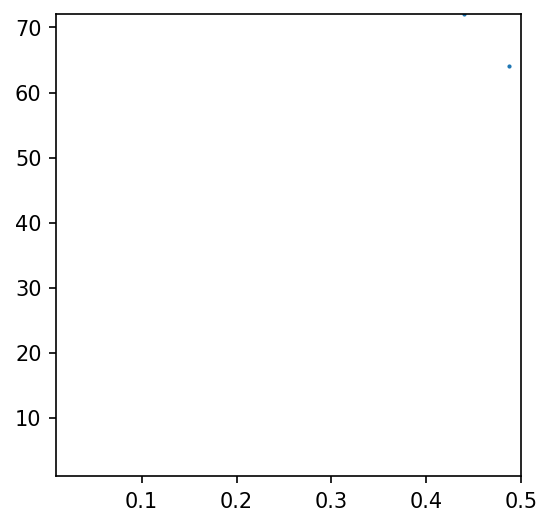

In [15]:
import numpy as np
from scipy.interpolate import interp1d

from RMFsolver.phase_velocity import extract_contour_coords_num
Deln_cut, T_cut = extract_contour_coords_num(D_grid, T_grid, a_diff.T, level=0)

# Suppose your arrays are:
# Deln_cut = np.array([...])   # x values
# T_cut = np.array([...])      # y values

# Define interpolation function: x = f(y)
Cut = interp1d(T_cut, Deln_cut, kind='linear', fill_value="extrapolate")

print(Cut(15)/n0)

# Example usage:
Tempr = np.linspace(1, 72, 10)
Del = np.array([Cut(Tempr[i]) for i in range(len(Tempr))])

plt.figure(figsize=[4,4])
plt.scatter(Del/n0, Tempr, s=1)
plt.xlim(0.01, 0.5)
plt.ylim(1, 72)

In [49]:
#np.save("Shade_n_crit="+str(nc/n0)+".npy", np.array([Deln_cut, T_cut]))

In [48]:
import numpy as np
import matplotlib.pyplot as plt

N = 30
meth = "numerical"
nc = 2*n0
m_strange = 0

TT = np.hstack([np.linspace(1, 20, int(N*2/5)),np.linspace(20.5, 72, int(N*3/5))])
DD = np.linspace(0.01*n0, 0.5*n0, N)

V = np.zeros([N, N])

for i in range(N):  # loop over T (rows)
    #DD = np.linspace(0.01*n0, np.minimum(0.5*n0, Cut(TT[i])-0.015*n0), N)
    for j in range(N):  # loop over B (columns)
        V[i,j], _ = vNtoQ_nc(
            T = TT[i],
            n_crit = nc,
            Deln = DD[j],
            m_s = m_strange,
            param = para.paraQMCRMF3,
            NM_type = "PNM",
            method = meth
        )
        print(i, j, V[i,j])

np.save("v_n_crit="+str(nc/n0)+".npy", V)

0 0 10.390663383450336
0 1 26.50708496039219
0 2 43.291356237808685
0 3 60.63477227397951
0 4 78.49798517206426
0 5 96.83224205822918
0 6 115.60194756934251
0 7 134.82552576230253
0 8 154.46384545543174
0 9 174.52555532166193
0 10 194.99840064656468
0 11 215.88280231309878
0 12 237.19934415747326
0 13 258.962340285896
0 14 281.13971907731025
0 15 303.7678436738881
0 16 326.8338280148352
0 17 350.3754774302458
0 18 374.3931915712027
0 19 398.92242605745594
0 20 423.9399419872799
0 21 449.5230334584825
0 22 475.6374476114231
0 23 502.33418820168674
0 24 529.6562489116656
0 25 557.582504153474
0 26 586.171187143924
0 27 615.4577648282967
0 28 645.4888140562273
0 29 676.2220939242709
1 0 7.108008564708179
1 1 14.652709118142191
1 2 22.037677426425702
1 3 29.533917326203458
1 4 37.18500359312086
1 5 45.00194737621285
1 6 52.99076610279751
1 7 61.146842225843436
1 8 69.47449473660824
1 9 77.97336587673533
1 10 86.63865764864269
1 11 95.47775718297527
1 12 104.4878780765097
1 13 113.677404460

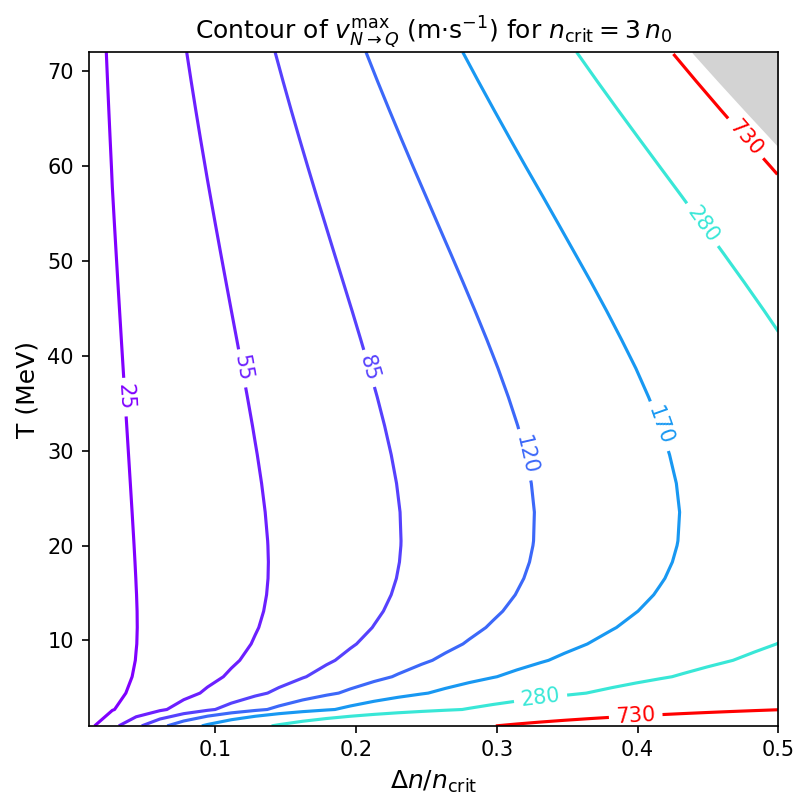

In [46]:
#np.array([25, 40, 55, 70, 90, 115, 150, 200])
# Inputs you already have:
# TT: (N,) temperatures
# V : (N, N) values with V[i, j] corresponding to (TT[i], DD[i, j])
# n0, nc, Cut: given in your code
N = len(TT)

# --- build the irregular structured grid ---
# along-row parameter (0..1) for each density sample
t = np.linspace(0.0, 1.0, N)

# upper bound for Δn at each TT[i]
Dmax = np.minimum(0.5 * n0, Cut(TT) - 0.015 * n0)           # shape (N,)

# ensure the upper bound is at least the lower bound to avoid inverted/degenerate rows
Dlo  = 0.01 * n0
Dmax = np.maximum(Dmax, Dlo)

# density grid: for each i, linspace(Dlo, Dmax[i], N)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]            # shape (N, N)

# temperature grid: each row equals TT[i]
T_grid = np.repeat(TT[:, None], N, axis=1)                   # shape (N, N)

# If V was stored transposed, fix it here so V[i,j] matches (T_grid[i,j], D_grid[i,j]).
Z = np.load("v_n_crit=3.0.npy") #if V.shape != D_grid.shape else V

# --- plot ---
plt.figure(figsize=(5.5, 5.5), dpi=150)

levels = np.array([25, 55, 85, 120, 170, 280, 730])
cs = plt.contour(D_grid / n0, T_grid, Z, levels=levels, cmap="rainbow")
plt.clabel(cs, inline=True, fontsize=10)

plt.title(r"Contour of $v_{N\to Q}^{\max}$ (m·s$^{-1}$) for $n_{\rm crit}=$"
          + f"{nc/n0:.3g}" + r"$\,n_0$")
plt.xlabel(r"$\Delta n / n_{\rm crit}$", fontsize=12)
plt.ylabel("T (MeV)", fontsize=12)
plt.tight_layout()

Dcut = Cut(TT)                    # shape (N,)
Dhi  = 0.5 * n0 * np.ones_like(TT)

# fill between Dcut and 0.5 n0, normalized by nc
plt.fill_betweenx(
    TT,                           # y-axis = temperatures
    Dcut / n0,                    # left boundary
    Dhi  / n0,                    # right boundary
    color="lightgrey", alpha=1, label="Excluded region"
)

plt.xlim(0.01, 0.5)
plt.ylim(1,72)

plt.show()